# 🫁 MedVision AI — GPU Training Pipeline
> **Data Workflow:**
> 1. Combine all raw data into 2 pools: `NORMAL` vs `PNEUMONIA`
> 2. Augment `NORMAL` to match `PNEUMONIA` (Exact 1:1 parity)
> 3. Split into `train` (80%), `val` (10%), and `test` (10%)
> 4. Train Baseline CNN vs ResNet-18, compare metrics, plot Grad-CAM & download `.pth` checkpoints

---
### ⚡ 1-Click Instructions:
1. **GPU Check**: Runtime → Change runtime type → **T4 GPU** → Save
2. Click **Runtime** → **Run all** (`Ctrl + F9`)
3. Sits back and watches everything run end-to-end automatically!

In [ ]:
# Cell 1: Check GPU Status
import torch
print('PyTorch Version:', torch.__version__)
print('CUDA Available :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU Device Name:', torch.cuda.get_device_name(0))
    print('GPU Memory     :', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), 'GB')
    device = torch.device('cuda')
else:
    print('⚠️ Running on CPU! For fast training, select T4 GPU in Runtime settings.')
    device = torch.device('cpu')

PyTorch Version: 2.11.0+cu130
CUDA Available : True
GPU Device Name: Tesla T4
GPU Memory     : 15.64 GB


In [ ]:
# Cell 2: Install Supporting Libraries
!pip install -q kagglehub grad-cam seaborn matplotlib scikit-learn tqdm pillow torchvision pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Cell 3: 2-Class Pooling -> Augment NORMAL -> 80/10/10 Split (~35s)
import os, random, hashlib, shutil
from pathlib import Path
from PIL import Image, ImageOps, ImageEnhance
import kagglehub

# Step 1: Clean any pre-existing macOS hidden files
!find /content -name "._*" -delete 2>/dev/null
!find /content -name ".DS_Store" -delete 2>/dev/null

# Step 2: Download raw dataset via kagglehub (~15 seconds)
print('📥 Step 1: Downloading raw dataset via kagglehub...')
raw_path = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')
!find "{raw_path}" -name "._*" -delete 2>/dev/null
!find "{raw_path}" -name ".DS_Store" -delete 2>/dev/null

raw_root = Path(raw_path)

# Step 3: Divide into 2 big pools: NORMAL and PNEUMONIA
print('\n📁 Step 2: Collecting all raw images into 2 class pools (NORMAL & PNEUMONIA)...')
def compute_hash(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

classes = ['NORMAL', 'PNEUMONIA']
pool = {'NORMAL': [], 'PNEUMONIA': []}
seen = set()

for cls in classes:
    for folder in raw_root.rglob(cls):
        if folder.is_dir():
            for f in folder.glob('*'):
                if f.name.startswith('.') or f.suffix.lower() not in ['.jpeg', '.jpg', '.png']:
                    continue
                file_hash = compute_hash(f)
                if file_hash not in seen:
                    seen.add(file_hash)
                    pool[cls].append(f)

print(f'  • Unique Clean NORMAL   : {len(pool["NORMAL"]):,} images')
print(f'  • Unique Clean PNEUMONIA: {len(pool["PNEUMONIA"]):,} images')

# Step 4: Medical Augmentation Function
def clinical_augment(img, rng):
    out = img.convert('RGB')
    if rng.random() > 0.5:
        out = ImageOps.mirror(out)
    angle = rng.uniform(-8.0, 8.0)
    out = out.rotate(angle, resample=Image.BILINEAR, fillcolor=(0, 0, 0))
    out = ImageEnhance.Contrast(out).enhance(rng.uniform(0.92, 1.08))
    out = ImageEnhance.Brightness(out).enhance(rng.uniform(0.92, 1.08))
    return out

# Step 5: Augment NORMAL pool to equal PNEUMONIA count
target_count = len(pool['PNEUMONIA'])
needed_aug = target_count - len(pool['NORMAL'])
print(f'\n⚙️ Step 3: Augmenting NORMAL (+{needed_aug:,} images) to equal PNEUMONIA ({target_count:,})...')

TEMP_POOL = Path('/content/temp_pool')
if TEMP_POOL.exists():
    shutil.rmtree(TEMP_POOL)
(TEMP_POOL / 'NORMAL').mkdir(parents=True, exist_ok=True)
(TEMP_POOL / 'PNEUMONIA').mkdir(parents=True, exist_ok=True)

# Copy PNEUMONIA to temp pool
for idx, f in enumerate(pool['PNEUMONIA']):
    shutil.copy2(f, TEMP_POOL / 'PNEUMONIA' / f'pneumonia_{idx+1:05d}.jpeg')

# Copy NORMAL originals to temp pool
for idx, f in enumerate(pool['NORMAL']):
    shutil.copy2(f, TEMP_POOL / 'NORMAL' / f'normal_orig_{idx+1:05d}.jpeg')

# Generate augmented NORMAL into temp pool
rng_aug = random.Random(42)
for i in range(needed_aug):
    src_f = pool['NORMAL'][i % len(pool['NORMAL'])]
    with Image.open(src_f) as base_img:
        aug = clinical_augment(base_img, rng_aug)
        aug.save(TEMP_POOL / 'NORMAL' / f'normal_aug_{i+1:05d}.jpeg', 'JPEG', quality=95)

all_norm = sorted(list((TEMP_POOL / 'NORMAL').glob('*.jp*g')))
all_pneu = sorted(list((TEMP_POOL / 'PNEUMONIA').glob('*.jp*g')))
print(f'  ✅ Both pools equalized: NORMAL={len(all_norm):,} | PNEUMONIA={len(all_pneu):,}')

# Step 6: Split both balanced pools into Train (80%), Val (10%), Test (10%)
DATA_DIR = Path('/content/data')
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)

print('\n✂️ Step 4: Splitting both balanced pools into Train (80%) / Val (10%) / Test (10%)...')
rng_split = random.Random(42)
rng_split.shuffle(all_norm)
rng_split.shuffle(all_pneu)

total_per_class = len(all_pneu)
n_train = int(total_per_class * 0.80)
n_val   = int(total_per_class * 0.10)

split_slices = {
    'train': (0, n_train),
    'val':   (n_train, n_train + n_val),
    'test':  (n_train + n_val, total_per_class)
}

for split_name, (start_idx, end_idx) in split_slices.items():
    s_norm_dir = DATA_DIR / split_name / 'NORMAL'
    s_pneu_dir = DATA_DIR / split_name / 'PNEUMONIA'
    s_norm_dir.mkdir(parents=True, exist_ok=True)
    s_pneu_dir.mkdir(parents=True, exist_ok=True)

    for f in all_norm[start_idx:end_idx]:
        shutil.copy2(f, s_norm_dir / f.name)
    for f in all_pneu[start_idx:end_idx]:
        shutil.copy2(f, s_pneu_dir / f.name)

# Remove temp pool
shutil.rmtree(TEMP_POOL)

# Step 7: Verify final folder counts on disk
print('\n' + '='*65)
print('✅ 50-50 BALANCED DATASET GENERATED SUCCESSFULLY ON DISK!')
print('='*65)
grand_total = 0
for s in ['train', 'val', 'test']:
    n_n = len(list((DATA_DIR / s / 'NORMAL').glob('*.jp*g')))
    n_p = len(list((DATA_DIR / s / 'PNEUMONIA').glob('*.jp*g')))
    tot = n_n + n_p
    grand_total += tot
    pct_n = (n_n / tot) * 100
    pct_p = (n_p / tot) * 100
    print(f'  📁 data/{s:5s} -> NORMAL: {n_n:,} ({pct_n:.1f}%) | PNEUMONIA: {n_p:,} ({pct_p:.1f}%) | Total: {tot:,}')
print('-'*65)
print(f'  🎉 Grand Total Images: {grand_total:,} (Exact 50.0% : 50.0%)')
print('='*65)

📥 Step 1: Downloading raw dataset via kagglehub...


100%|██████████| 2.29G/2.29G [00:28<00:00, 87.9MB/s]

Extracting files...



📁 Step 2: Collecting all raw images into 2 class pools (NORMAL & PNEUMONIA)...
  • Unique Clean NORMAL   : 1,579 images
  • Unique Clean PNEUMONIA: 4,245 images

⚙️ Step 3: Augmenting NORMAL (+2,666 images) to equal PNEUMONIA (4,245)...
  ✅ Both pools equalized: NORMAL=4,245 | PNEUMONIA=4,245

✂️ Step 4: Splitting both balanced pools into Train (80%) / Val (10%) / Test (10%)...

✅ 50-50 BALANCED DATASET GENERATED SUCCESSFULLY ON DISK!
  📁 data/train -> NORMAL: 3,396 (50.0%) | PNEUMONIA: 3,396 (50.0%) | Total: 6,792
  📁 data/val   -> NORMAL: 424 (50.0%) | PNEUMONIA: 424 (50.0%) | Total: 848
  📁 data/test  -> NORMAL: 425 (50.0%) | PNEUMONIA: 425 (50.0%) | Total: 850
-----------------------------------------------------------------
  🎉 Grand Total Images: 8,490 (Exact 50.0% : 50.0%)


In [ ]:
# Cell 4: PyTorch DataLoaders (Directly from /content/data)
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 64
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_ds = ImageFolder(str(DATA_DIR / 'train'), transform=train_tf)
val_ds   = ImageFolder(str(DATA_DIR / 'val'),   transform=val_tf)
test_ds  = ImageFolder(str(DATA_DIR / 'test'),  transform=val_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print('✅ DataLoaders initialized successfully!')
print(f'  Classes: {train_ds.classes} (0={train_ds.classes[0]}, 1={train_ds.classes[1]})')
print(f'  Train: {len(train_ds):,} images | Val: {len(val_ds):,} images | Test: {len(test_ds):,} images')
print(f'  Train Batches: {len(train_loader)} | Val Batches: {len(val_loader)} | Test Batches: {len(test_loader)}')

✅ DataLoaders initialized successfully!
  Classes: ['NORMAL', 'PNEUMONIA'] (0=NORMAL, 1=PNEUMONIA)
  Train: 6,792 images | Val: 848 images | Test: 850 images
  Train Batches: 107 | Val Batches: 14 | Test Batches: 14


In [ ]:
# Cell 5: Model 1 — Custom Baseline CNN (Built from scratch)
import torch.nn as nn

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(BaselineCNN, self).__init__()
        self.features = nn.Sequential(
            # Conv Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.LeakyReLU(0.1), nn.MaxPool2d(2, 2),
            # Conv Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.1), nn.MaxPool2d(2, 2),
            # Conv Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.1), nn.MaxPool2d(2, 2),
            # Conv Block 4
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.1),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

cnn_model = BaselineCNN().to(device)
print(f'Baseline CNN instantiated. Total parameters: {sum(p.numel() for p in cnn_model.parameters()):,}')

Baseline CNN instantiated. Total parameters: 249,922


In [ ]:
# Cell 6: Metrics Evaluation Engine
import time, numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def eval_epoch(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

def compute_test_metrics(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    rec = recall_score(all_labels, all_preds)   # Sensitivity (Missing zero sick patients)
    prec = precision_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)
    spec = cm[0,0] / (cm[0,0] + cm[0,1]) if (cm[0,0] + cm[0,1]) > 0 else 0
    return {'accuracy': acc, 'recall': rec, 'precision': prec, 'specificity': spec, 'f1': f1, 'auc': auc, 'cm': cm}

In [ ]:
# Cell 7: Train Model 1 (Baseline CNN)
print('='*55)
print('🚀 STEP 1: TRAINING BASELINE CNN (FROM SCRATCH)')
print('='*55)

cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)
cnn_epochs = 10
best_val_acc = 0.0

start_t = time.time()
for epoch in range(1, cnn_epochs + 1):
    tr_loss, tr_acc = train_epoch(cnn_model, train_loader, cnn_criterion, cnn_optimizer)
    va_loss, va_acc = eval_epoch(cnn_model, val_loader, cnn_criterion)
    print(f'Epoch {epoch:02d}/{cnn_epochs} | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.1f}% | Val Loss: {va_loss:.4f} Acc: {va_acc*100:.1f}%')
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(cnn_model.state_dict(), 'best_cnn.pth')

cnn_time = time.time() - start_t
print(f'\nBaseline CNN training finished in {cnn_time/60:.1f} mins.')

# Evaluate CNN on Test Set
if os.path.exists('best_cnn.pth'):
    cnn_model.load_state_dict(torch.load('best_cnn.pth'))
cnn_metrics = compute_test_metrics(cnn_model, test_loader)
print('\n📊 Baseline CNN Test Set Metrics:')
print(f'  Accuracy          : {cnn_metrics["accuracy"]*100:.2f}%')
print(f'  Sensitivity/Recall: {cnn_metrics["recall"]*100:.2f}%')
print(f'  Specificity       : {cnn_metrics["specificity"]*100:.2f}%')
print(f'  F1-Score          : {cnn_metrics["f1"]*100:.2f}%')
print(f'  ROC-AUC           : {cnn_metrics["auc"]*100:.2f}%')

🚀 STEP 1: TRAINING BASELINE CNN (FROM SCRATCH)
Epoch 01/10 | Train Loss: 0.3480 Acc: 86.0% | Val Loss: 0.2717 Acc: 88.6%
Epoch 02/10 | Train Loss: 0.2551 Acc: 89.9% | Val Loss: 0.3260 Acc: 87.5%
Epoch 03/10 | Train Loss: 0.2133 Acc: 91.9% | Val Loss: 0.1875 Acc: 92.2%
Epoch 04/10 | Train Loss: 0.1913 Acc: 93.0% | Val Loss: 0.4046 Acc: 85.1%
Epoch 05/10 | Train Loss: 0.1842 Acc: 93.0% | Val Loss: 0.3237 Acc: 88.1%
Epoch 06/10 | Train Loss: 0.1723 Acc: 93.4% | Val Loss: 0.1396 Acc: 94.3%
Epoch 07/10 | Train Loss: 0.1538 Acc: 94.3% | Val Loss: 0.1731 Acc: 93.9%
Epoch 08/10 | Train Loss: 0.1587 Acc: 94.3% | Val Loss: 0.2083 Acc: 91.7%
Epoch 09/10 | Train Loss: 0.1491 Acc: 94.8% | Val Loss: 0.1945 Acc: 92.7%
Epoch 10/10 | Train Loss: 0.1613 Acc: 93.9% | Val Loss: 0.1577 Acc: 93.8%

Baseline CNN training finished in 22.1 mins.

📊 Baseline CNN Test Set Metrics:
  Accuracy          : 94.71%
  Sensitivity/Recall: 92.71%
  Specificity       : 96.71%
  F1-Score          : 94.60%
  ROC-AUC        

In [ ]:
# Cell 8: Model 2 — ResNet-18 Transfer Learning Architecture
from torchvision import models

class MedVisionResNet(nn.Module):
    def __init__(self, num_classes=2):
        super(MedVisionResNet, self).__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        in_features = self.backbone.fc.in_features  # 512
        self.backbone.fc = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes)
        )
    def forward(self, x):
        return self.backbone(x)

resnet_model = MedVisionResNet().to(device)
print(f'ResNet-18 instantiated. Total parameters: {sum(p.numel() for p in resnet_model.parameters()):,}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]

ResNet-18 instantiated. Total parameters: 11,177,538


In [ ]:
# Cell 9: Train Model 2 (ResNet-18 Transfer Learning)
print('='*55)
print('🚀 STEP 2: TRAINING RESNET-18 (TRANSFER LEARNING)')
print('='*55)

res_criterion = nn.CrossEntropyLoss()
res_optimizer = torch.optim.AdamW(resnet_model.parameters(), lr=0.0003, weight_decay=1e-4)
res_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(res_optimizer, T_max=10)
res_epochs = 10
best_res_acc = 0.0

start_t = time.time()
for epoch in range(1, res_epochs + 1):
    tr_loss, tr_acc = train_epoch(resnet_model, train_loader, res_criterion, res_optimizer)
    va_loss, va_acc = eval_epoch(resnet_model, val_loader, res_criterion)
    res_scheduler.step()
    print(f'Epoch {epoch:02d}/{res_epochs} | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.1f}% | Val Loss: {va_loss:.4f} Acc: {va_acc*100:.1f}%')
    if va_acc > best_res_acc:
        best_res_acc = va_acc
        torch.save(resnet_model.state_dict(), 'best_resnet18.pth')

res_time = time.time() - start_t
print(f'\nResNet-18 training finished in {res_time/60:.1f} mins.')

# Evaluate ResNet-18 on Test Set
if os.path.exists('best_resnet18.pth'):
    resnet_model.load_state_dict(torch.load('best_resnet18.pth'))
res_metrics = compute_test_metrics(resnet_model, test_loader)
print('\n📊 ResNet-18 Test Set Metrics:')
print(f'  Accuracy          : {res_metrics["accuracy"]*100:.2f}%')
print(f'  Sensitivity/Recall: {res_metrics["recall"]*100:.2f}%')
print(f'  Specificity       : {res_metrics["specificity"]*100:.2f}%')
print(f'  F1-Score          : {res_metrics["f1"]*100:.2f}%')
print(f'  ROC-AUC           : {res_metrics["auc"]*100:.2f}%')

🚀 STEP 2: TRAINING RESNET-18 (TRANSFER LEARNING)
Epoch 01/10 | Train Loss: 0.1242 Acc: 95.5% | Val Loss: 0.0761 Acc: 96.7%
Epoch 02/10 | Train Loss: 0.0812 Acc: 97.2% | Val Loss: 0.0719 Acc: 96.8%
Epoch 03/10 | Train Loss: 0.0738 Acc: 97.3% | Val Loss: 0.0362 Acc: 98.5%
Epoch 04/10 | Train Loss: 0.0425 Acc: 98.6% | Val Loss: 0.0321 Acc: 98.9%
Epoch 05/10 | Train Loss: 0.0340 Acc: 98.7% | Val Loss: 0.0753 Acc: 98.1%
Epoch 06/10 | Train Loss: 0.0283 Acc: 99.1% | Val Loss: 0.0365 Acc: 98.7%
Epoch 07/10 | Train Loss: 0.0198 Acc: 99.3% | Val Loss: 0.0223 Acc: 99.3%
Epoch 08/10 | Train Loss: 0.0140 Acc: 99.5% | Val Loss: 0.0232 Acc: 99.3%
Epoch 09/10 | Train Loss: 0.0121 Acc: 99.6% | Val Loss: 0.0240 Acc: 99.4%
Epoch 10/10 | Train Loss: 0.0082 Acc: 99.8% | Val Loss: 0.0238 Acc: 99.4%

ResNet-18 training finished in 22.4 mins.

📊 ResNet-18 Test Set Metrics:
  Accuracy          : 99.06%
  Sensitivity/Recall: 98.59%
  Specificity       : 99.53%
  F1-Score          : 99.05%
  ROC-AUC           :


🏆 BASELINE CNN vs RESNET-18 COMPARATIVE CLINICAL STUDY


,Metric,Baseline CNN (Scratch),ResNet-18 (Transfer Learning),Net Improvement
0,Architecture,Custom 4-Block CNN,ResNet-18 Pretrained,Residual Skip Connections
1,Parameters,"249,922","11,177,538",ImageNet Pretrained Priors
2,Training Time,22.1 min,22.4 min,+0.3 min
3,Test Accuracy,94.71%,99.06%,+4.35%
4,Sensitivity / Recall,92.71%,98.59%,+5.88%
5,Specificity,96.71%,99.53%,+2.82%
6,F1-Score,94.60%,99.05%,+4.46%
7,ROC-AUC,99.02%,99.94%,+0.91%


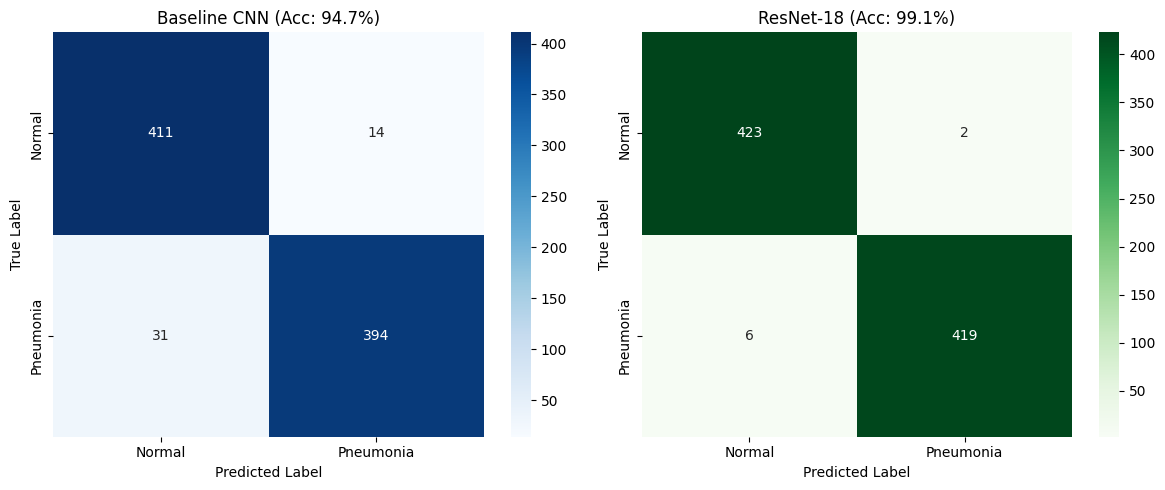

In [ ]:
# Cell 10: Comparison Table & Confusion Matrices
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison_df = pd.DataFrame({
    'Metric': ['Architecture', 'Parameters', 'Training Time', 'Test Accuracy', 'Sensitivity / Recall', 'Specificity', 'F1-Score', 'ROC-AUC'],
    'Baseline CNN (Scratch)': [
        'Custom 4-Block CNN',
        f'{sum(p.numel() for p in cnn_model.parameters()):,}',
        f'{cnn_time/60:.1f} min',
        f'{cnn_metrics["accuracy"]*100:.2f}%',
        f'{cnn_metrics["recall"]*100:.2f}%',
        f'{cnn_metrics["specificity"]*100:.2f}%',
        f'{cnn_metrics["f1"]*100:.2f}%',
        f'{cnn_metrics["auc"]*100:.2f}%',
    ],
    'ResNet-18 (Transfer Learning)': [
        'ResNet-18 Pretrained',
        f'{sum(p.numel() for p in resnet_model.parameters()):,}',
        f'{res_time/60:.1f} min',
        f'{res_metrics["accuracy"]*100:.2f}%',
        f'{res_metrics["recall"]*100:.2f}%',
        f'{res_metrics["specificity"]*100:.2f}%',
        f'{res_metrics["f1"]*100:.2f}%',
        f'{res_metrics["auc"]*100:.2f}%',
    ],
    'Net Improvement': [
        'Residual Skip Connections',
        'ImageNet Pretrained Priors',
        f'{(res_time - cnn_time)/60:+.1f} min',
        f'{(res_metrics["accuracy"] - cnn_metrics["accuracy"])*100:+.2f}%',
        f'{(res_metrics["recall"] - cnn_metrics["recall"])*100:+.2f}%',
        f'{(res_metrics["specificity"] - cnn_metrics["specificity"])*100:+.2f}%',
        f'{(res_metrics["f1"] - cnn_metrics["f1"])*100:+.2f}%',
        f'{(res_metrics["auc"] - cnn_metrics["auc"])*100:+.2f}%',
    ]
})

print('\n' + '='*75)
print('🏆 BASELINE CNN vs RESNET-18 COMPARATIVE CLINICAL STUDY')
print('='*75)
display(comparison_df)

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cnn_metrics['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
axes[0].set_title(f'Baseline CNN (Acc: {cnn_metrics["accuracy"]*100:.1f}%)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(res_metrics['cm'], annot=True, fmt='d', cmap='Greens', ax=axes[1], xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
axes[1].set_title(f'ResNet-18 (Acc: {res_metrics["accuracy"]*100:.1f}%)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrices_comparison.png', dpi=200)
plt.show()

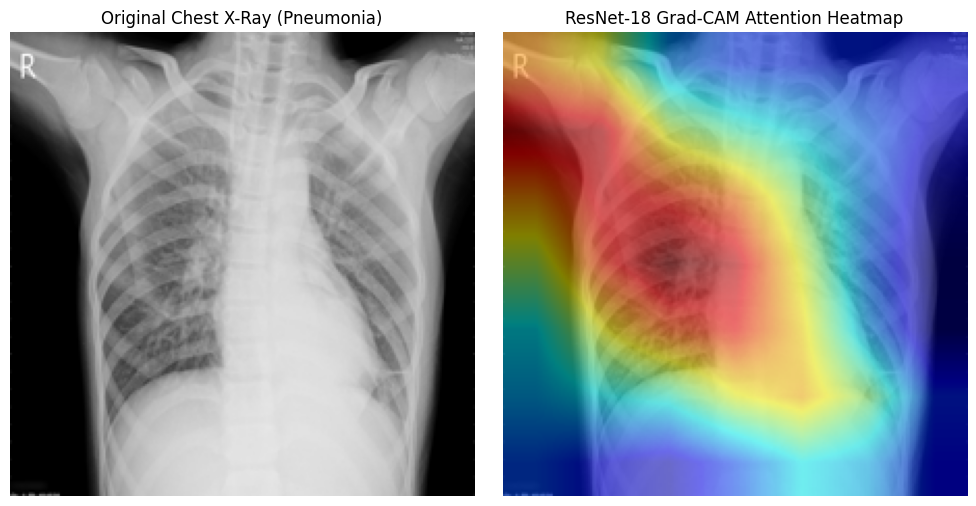

In [ ]:
# Cell 11: Grad-CAM Explainability Demonstration
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Pick a test pneumonia image
pneu_test_files = [p for p in (DATA_DIR / 'test' / 'PNEUMONIA').glob('*') if not p.name.startswith('.')]
sample_path = pneu_test_files[0]
raw_img = Image.open(sample_path).convert('RGB').resize((224, 224))
input_tensor = val_tf(raw_img).unsqueeze(0).to(device)
rgb_norm = np.array(raw_img, dtype=np.float32) / 255.0

# Generate Grad-CAM for ResNet-18 layer4
target_layers = [resnet_model.backbone.layer4[-1]]
cam = GradCAM(model=resnet_model, target_layers=target_layers)
grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(1)])[0, :]
cam_image = show_cam_on_image(rgb_norm, grayscale_cam, use_rgb=True)

# Display side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(raw_img)
axes[0].set_title('Original Chest X-Ray (Pneumonia)')
axes[0].axis('off')

axes[1].imshow(cam_image)
axes[1].set_title('ResNet-18 Grad-CAM Attention Heatmap')
axes[1].axis('off')
plt.tight_layout()
plt.savefig('gradcam_sample.png', dpi=200)
plt.show()

In [ ]:
# Cell 12: Download Trained Weights & Charts (.zip)
import zipfile
try:
    from google.colab import files
    is_colab = True
except ImportError:
    is_colab = False

print('📦 Packaging trained models and comparison reports...')
zip_filename = 'medvision_colab_artifacts.zip'
with zipfile.ZipFile(zip_filename, 'w') as zf:
    for f in ['best_resnet18.pth', 'best_cnn.pth', 'confusion_matrices_comparison.png', 'gradcam_sample.png']:
        if os.path.exists(f):
            zf.write(f, arcname=f)
            print(f'  + Bundled {f}')

if is_colab:
    print('\n📥 Triggering browser download of medvision_colab_artifacts.zip...')
    files.download(zip_filename)
else:
    print(f'\n✅ Saved artifacts bundle at: {os.path.abspath(zip_filename)}')

print('\n🎉 ALL DONE! Place best_resnet18.pth and best_cnn.pth into artifacts/checkpoints/ to run your Streamlit diagnosis app!')

📦 Packaging trained models and comparison reports...
  + Bundled best_resnet18.pth
  + Bundled best_cnn.pth
  + Bundled confusion_matrices_comparison.png
  + Bundled gradcam_sample.png

📥 Triggering browser download of medvision_colab_artifacts.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 ALL DONE! Place best_resnet18.pth and best_cnn.pth into artifacts/checkpoints/ to run your Streamlit diagnosis app!
